<a href="https://colab.research.google.com/github/Kishore-Krish19/ML/blob/main/Sentiment_Analysis_Comparision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Sentiment Analysis on dataset by building and comparing NN, RNN, LST and GRU**

In [1]:
!pip -q install datasets pandas matplotlib seaborn scikit-learn optuna

Loading the Dataset

In [2]:
from datasets import load_dataset
import pandas as pd
import torch

dataset = load_dataset(
    "Sp1786/multiclass-sentiment-analysis-dataset"
)

print(dataset)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})
PyTorch version: 2.14.1+cpu
GPU available: False


EDA

In [3]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nFirst five training records:")
print(train_df.head())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nDuplicate training texts:")
print(train_df["text"].duplicated().sum())

Training samples: 31232
Validation samples: 5205
Testing samples: 5206

First five training records:
      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative

Missing values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64

Duplicate training texts:
0


Data Distribution analysis

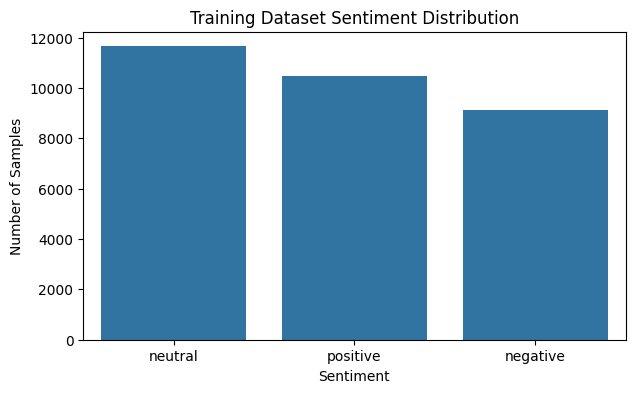

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count samples for each sentiment
sentiment_counts = train_df["sentiment"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 4))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Training Dataset Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")

plt.show()

Text Processing:

In [5]:
from collections import Counter

# Tokenize the training sentences
train_tokens = [
    str(text).lower().split()
    for text in train_df["text"]
]

# Count occurrences of words
word_counts = Counter(
    word for sentence in train_tokens
    for word in sentence
)

# Set vocabulary size
MAX_VOCAB_SIZE = 10000

# Reserve IDs for special tokens
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Add the most frequent words
for word, count in word_counts.most_common(
    MAX_VOCAB_SIZE - 2
):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("First 10 vocabulary entries:")
print(list(vocab.items())[:10])

Vocabulary size: 10000
First 10 vocabulary entries:
[('<PAD>', 0), ('<UNK>', 1), ('i', 2), ('the', 3), ('to', 4), ('a', 5), ('and', 6), ('it', 7), ('my', 8), ('is', 9)]


Convert sentences into numerical sequences

In [6]:
MAX_LENGTH = 64

def encode_text(text):
    tokens = str(text).lower().split()

    # Convert each word to a token ID
    sequence = [
        vocab.get(word, vocab["<UNK>"])
        for word in tokens
    ]

    # Truncate longer sequences
    sequence = sequence[:MAX_LENGTH]

    # Pad shorter sequences
    sequence += [vocab["<PAD>"]] * (
        MAX_LENGTH - len(sequence)
    )

    return sequence

example = train_df["text"].iloc[0]

print("Original text:", example)
print("Encoded sequence:", encode_text(example))
print("Sequence length:", len(encode_text(example)))

Original text: Cooking microwave pizzas, yummy
Encoded sequence: [3040, 1, 8473, 1864, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Sequence length: 64


Pytorch Tensors

In [7]:
import numpy as np
import torch

# Encode text for each dataset split
X_train = np.array(
    [encode_text(text) for text in train_df["text"]],
    dtype=np.int64
)

X_val = np.array(
    [encode_text(text) for text in val_df["text"]],
    dtype=np.int64
)

X_test = np.array(
    [encode_text(text) for text in test_df["text"]],
    dtype=np.int64
)

# Sentiment labels
y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)

# Convert arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.long)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training input shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Validation input shape:", X_val.shape)
print("Test input shape:", X_test.shape)

Training input shape: torch.Size([31232, 64])
Training labels shape: torch.Size([31232])
Validation input shape: torch.Size([5205, 64])
Test input shape: torch.Size([5206, 64])


Check how much text gets truncated

In [8]:
lengths = [len(tokens) for tokens in train_tokens]

print("Median sentence length:", np.median(lengths))
print("95th percentile length:", np.percentile(lengths, 95))
print("Longest sentence:", max(lengths))

truncated = sum(
    length > MAX_LENGTH for length in lengths
)

print(
    "Percentage of training sentences truncated:",
    round(100 * truncated / len(lengths), 2),
    "%"
)

Median sentence length: 13.0
95th percentile length: 56.0
Longest sentence: 391
Percentage of training sentences truncated: 3.96 %


Feedforward Neural Network

In [9]:
import torch
import torch.nn as nn

class SentimentNN(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128,
                 hidden_dim=64, num_classes=3):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):

        # Convert token IDs into embeddings
        embedded = self.embedding(x)

        # Ignore padding when computing sentence average
        mask = (x != 0).unsqueeze(-1)

        summed = (embedded * mask).sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1)

        pooled = summed / lengths

        # Fully connected layers
        hidden = self.relu(self.fc1(pooled))
        output = self.fc2(hidden)

        return output

Output Inspection

In [10]:
# Select CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create the model
model = SentimentNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_classes=3
).to(device)

print(model)

# Test with four training sentences
sample_input = X_train[:4].to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("\nInput shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("\nRaw output scores:")
print(sample_output)

SentimentNN(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=3, bias=True)
)

Input shape: torch.Size([4, 64])
Output shape: torch.Size([4, 3])

Raw output scores:
tensor([[-0.0254,  0.0909, -0.0042],
        [ 0.0338,  0.0464,  0.1405],
        [-0.0407,  0.0554,  0.0600],
        [-0.0994, -0.0434, -0.0049]])


Prepare training batches

In [11]:
from torch.utils.data import TensorDataset, DataLoader

# Combine input sentences and their labels
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

# Choose batch size
BATCH_SIZE = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 976
Validation batches: 163


Loss function and optimizer

In [12]:
import torch.nn as nn
import torch.optim as optim

# Loss function for 3-class classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


Train the Neural Network for one epoch

In [13]:
# Put model in training mode
model.train()

total_loss = 0.0
correct = 0
total = 0

for inputs, labels in train_loader:

    # Move tensors to CPU or GPU
    inputs = inputs.to(device)
    labels = labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(inputs)

    # Compute loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    # Track results
    total_loss += loss.item() * labels.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

train_loss = total_loss / total
train_accuracy = correct / total

print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.4f}")

Training loss: 0.9505
Training accuracy: 0.5282


In [14]:
from sklearn.metrics import accuracy_score, f1_score
import torch

# Switch model to evaluation mode
model.eval()

all_predictions = []
all_labels = []

# Disable gradient calculations
with torch.no_grad():

    for inputs, labels in val_loader:

        inputs = inputs.to(device)

        # Generate predictions
        outputs = model(inputs)

        # Select class with highest score
        predictions = outputs.argmax(dim=1)

        # Collect predictions and true labels
        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            labels.tolist()
        )

# Calculate evaluation metrics
val_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

val_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro-F1: {val_macro_f1:.4f}")

Validation Accuracy: 0.5927
Validation Macro-F1: 0.5939


Validation Function

In [15]:
from sklearn.metrics import accuracy_score, f1_score
import torch

def evaluate_model(model, data_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in data_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    avg_loss = total_loss / len(data_loader.dataset)

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

Training function for one epoch

In [16]:
def train_one_epoch(model, train_loader,
                    criterion, optimizer, device):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

Combine training, validation, and early stopping

In [17]:
import copy

def train_model(model, train_loader, val_loader,
                criterion, optimizer, device,
                epochs=10, patience=3):

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_f1": []
    }

    best_f1 = -1.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    no_improvement = 0

    for epoch in range(1, epochs + 1):

        # Train for one epoch
        train_loss, train_acc = train_one_epoch(
            model, train_loader,
            criterion, optimizer, device
        )

        # Evaluate on validation dataset
        val_loss, val_acc, val_f1 = evaluate_model(
            model, val_loader, criterion, device
        )

        # Store results
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)
        history["val_f1"].append(val_f1)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        # Check whether validation F1 improved
        if val_f1 > best_f1 + 1e-4:

            best_f1 = val_f1
            best_epoch = epoch
            best_weights = copy.deepcopy(
                model.state_dict()
            )

            no_improvement = 0

        else:
            no_improvement += 1

        # Early stopping condition
        if no_improvement >= patience:
            print("Early stopping triggered!")
            break

    # Restore the best model
    model.load_state_dict(best_weights)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation macro-F1: {best_f1:.4f}")

    return model, history

Train the NN using the new functions

In [18]:
# Set random seed for reproducibility
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Create a fresh Neural Network
nn_model = SentimentNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_classes=3
).to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Fresh optimizer
nn_optimizer = torch.optim.Adam(
    nn_model.parameters(),
    lr=0.001
)

# Train with early stopping
nn_model, nn_history = train_model(
    model=nn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=nn_optimizer,
    device=device,
    epochs=10,
    patience=3
)

Epoch 1/10 | Train Loss: 0.9474 | Train Acc: 0.5254 | Val Loss: 0.8594 | Val Acc: 0.5894 | Val F1: 0.5887
Epoch 2/10 | Train Loss: 0.7891 | Train Acc: 0.6429 | Val Loss: 0.8244 | Val Acc: 0.6179 | Val F1: 0.6189
Epoch 3/10 | Train Loss: 0.7034 | Train Acc: 0.6940 | Val Loss: 0.7891 | Val Acc: 0.6405 | Val F1: 0.6436
Epoch 4/10 | Train Loss: 0.6386 | Train Acc: 0.7293 | Val Loss: 0.7904 | Val Acc: 0.6492 | Val F1: 0.6518
Epoch 5/10 | Train Loss: 0.5870 | Train Acc: 0.7538 | Val Loss: 0.8100 | Val Acc: 0.6478 | Val F1: 0.6508
Epoch 6/10 | Train Loss: 0.5419 | Train Acc: 0.7776 | Val Loss: 0.8445 | Val Acc: 0.6515 | Val F1: 0.6548
Epoch 7/10 | Train Loss: 0.5023 | Train Acc: 0.7975 | Val Loss: 0.8667 | Val Acc: 0.6415 | Val F1: 0.6441
Epoch 8/10 | Train Loss: 0.4663 | Train Acc: 0.8120 | Val Loss: 0.9029 | Val Acc: 0.6384 | Val F1: 0.6410
Epoch 9/10 | Train Loss: 0.4299 | Train Acc: 0.8314 | Val Loss: 0.9688 | Val Acc: 0.6342 | Val F1: 0.6368
Early stopping triggered!

Best epoch: 6
Best 

Visualization graphs

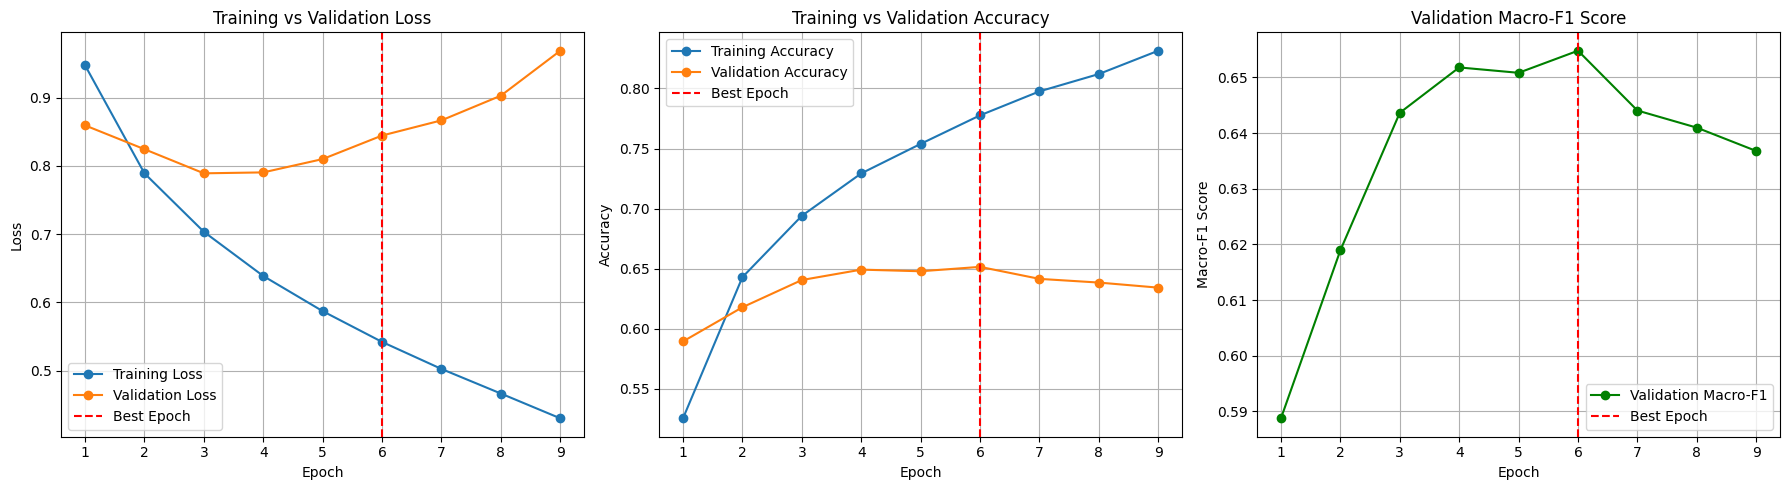

Best Epoch: 6
Best Validation Macro-F1: 0.6548


In [19]:
import matplotlib.pyplot as plt

# Get the number of completed epochs
epochs = range(1, len(nn_history["train_loss"]) + 1)

# Find the best epoch using validation macro-F1
best_epoch = nn_history["val_f1"].index(
    max(nn_history["val_f1"])
) + 1

plt.figure(figsize=(18, 5))

# Graph 1: Training and Validation Loss
plt.subplot(1, 3, 1)

plt.plot(epochs, nn_history["train_loss"],
         marker="o", label="Training Loss")

plt.plot(epochs, nn_history["val_loss"],
         marker="o", label="Validation Loss")

plt.axvline(best_epoch, color="red",
            linestyle="--", label="Best Epoch")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Graph 2: Training and Validation Accuracy
plt.subplot(1, 3, 2)

plt.plot(epochs, nn_history["train_accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(epochs, nn_history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.axvline(best_epoch, color="red",
            linestyle="--", label="Best Epoch")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Graph 3: Validation Macro-F1 Score
plt.subplot(1, 3, 3)

plt.plot(epochs, nn_history["val_f1"],
         marker="o", color="green",
         label="Validation Macro-F1")

plt.axvline(best_epoch, color="red",
            linestyle="--", label="Best Epoch")

plt.title("Validation Macro-F1 Score")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1 Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Best Epoch:", best_epoch)
print("Best Validation Macro-F1:",
      round(max(nn_history["val_f1"]), 4))

Save and Verify the NN Baseline

In [20]:
import os
import torch

os.makedirs("saved_models", exist_ok=True)

torch.save(
    {
        "model_state_dict": nn_model.state_dict(),
        "vocab": vocab,
        "max_length": MAX_LENGTH,
        "embedding_dim": 128,
        "hidden_dim": 64,
        "num_classes": 3,
        "best_val_f1": max(nn_history["val_f1"])
    },
    "saved_models/nn_baseline.pth"
)

print("NN baseline model saved successfully!")

NN baseline model saved successfully!


Verifying the best model

In [21]:
nn_val_loss, nn_val_acc, nn_val_f1 = evaluate_model(
    nn_model,
    val_loader,
    criterion,
    device
)

print(f"Validation Loss: {nn_val_loss:.4f}")
print(f"Validation Accuracy: {nn_val_acc:.4f}")
print(f"Validation Macro-F1: {nn_val_f1:.4f}")

Validation Loss: 0.8445
Validation Accuracy: 0.6515
Validation Macro-F1: 0.6548


Comparing all the Models

In [22]:
!pip -q install optuna scikit-learn seaborn

import os
import json
import copy
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import optuna

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch version:", torch.__version__)

# Experiment configuration
MAX_EPOCHS = 8
PATIENCE = 2
N_TRIALS = 8

MODEL_NAMES = ["NN", "RNN", "LSTM", "GRU"]
CLASS_NAMES = ["negative", "neutral", "positive"]

os.makedirs("results", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

Device: cpu
PyTorch version: 2.14.1+cpu


Preparing the dataset

In [23]:
# Ensure all sequences use the same maximum length
MAX_LENGTH = 64

X_train = torch.tensor(
    [encode_text(t) for t in train_df["text"]],
    dtype=torch.long
)

X_val = torch.tensor(
    [encode_text(t) for t in val_df["text"]],
    dtype=torch.long
)

X_test = torch.tensor(
    [encode_text(t) for t in test_df["text"]],
    dtype=torch.long
)

y_train = torch.tensor(
    train_df["label"].to_numpy(),
    dtype=torch.long
)

y_val = torch.tensor(
    val_df["label"].to_numpy(),
    dtype=torch.long
)

y_test = torch.tensor(
    test_df["label"].to_numpy(),
    dtype=torch.long
)

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

VOCAB_SIZE = len(vocab)
NUM_CLASSES = 3

assert X_train.shape[1] == 64
assert X_val.shape[1] == 64
assert X_test.shape[1] == 64
assert set(y_train.tolist()) == {0, 1, 2}

print("Vocabulary size:", VOCAB_SIZE)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Vocabulary size: 10000
Training: torch.Size([31232, 64])
Validation: torch.Size([5205, 64])
Testing: torch.Size([5206, 64])


Building all four models

In [24]:
class SentimentModel(nn.Module):

    def __init__(
        self,
        model_type,
        vocab_size,
        embedding_dim=128,
        hidden_dim=64,
        num_layers=1,
        dropout=0.3,
        num_classes=3
    ):
        super().__init__()

        self.model_type = model_type

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.dropout = nn.Dropout(dropout)

        if model_type == "NN":

            self.hidden_layers = nn.ModuleList()

            input_dim = embedding_dim

            for _ in range(num_layers):
                self.hidden_layers.append(
                    nn.Linear(input_dim, hidden_dim)
                )
                input_dim = hidden_dim

        elif model_type in ["RNN", "LSTM", "GRU"]:

            rnn_class = {
                "RNN": nn.RNN,
                "LSTM": nn.LSTM,
                "GRU": nn.GRU
            }[model_type]

            self.recurrent = rnn_class(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout if num_layers > 1 else 0
            )

        else:
            raise ValueError("Unknown model type")

        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):

        embedded = self.embedding(x)

        if self.model_type == "NN":

            # Mean pooling excluding padding tokens
            mask = (x != 0).unsqueeze(-1)

            summed = (embedded * mask).sum(dim=1)

            lengths = mask.sum(dim=1).clamp(min=1)

            hidden = summed / lengths

            for layer in self.hidden_layers:
                hidden = torch.relu(layer(hidden))
                hidden = self.dropout(hidden)

        else:

            # Real sequence lengths without padding
            lengths = (x != 0).sum(dim=1).clamp(min=1)

            packed = pack_padded_sequence(
                embedded,
                lengths.cpu(),
                batch_first=True,
                enforce_sorted=False
            )

            if self.model_type == "LSTM":

                _, (hidden_state, cell_state) = (
                    self.recurrent(packed)
                )

            else:

                _, hidden_state = self.recurrent(packed)

            # Final layer's final hidden state
            hidden = hidden_state[-1]

            hidden = self.dropout(hidden)

        return self.fc(hidden)

Verify Model Architecture

In [25]:
for model_name in MODEL_NAMES:

    model = SentimentModel(
        model_type=model_name,
        vocab_size=VOCAB_SIZE
    ).to(device)

    sample = X_train[:4].to(device)

    with torch.no_grad():
        output = model(sample)

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    print(
        f"{model_name:5s} | "
        f"Output: {tuple(output.shape)} | "
        f"Parameters: {parameters:,}"
    )

NN    | Output: (4, 3) | Parameters: 1,288,451
RNN   | Output: (4, 3) | Parameters: 1,292,611
LSTM  | Output: (4, 3) | Parameters: 1,329,859
GRU   | Output: (4, 3) | Parameters: 1,317,443


Training and Evaluation function

In [26]:
def make_loaders(batch_size):

    generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader


def evaluate(model, loader, criterion):

    model.eval()

    all_preds = []
    all_true = []
    total_loss = 0.0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_true.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    metrics = {
        "loss": avg_loss,
        "accuracy": accuracy_score(all_true, all_preds),
        "precision": precision_score(
            all_true, all_preds,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            all_true, all_preds,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            all_true, all_preds,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )
    }

    return metrics


def train_experiment(
    model,
    train_loader,
    val_loader,
    learning_rate,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    best_f1 = -1.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    wait = 0

    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)

            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        val_metrics = evaluate(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        # Select best model by validation macro-F1
        if val_metrics["macro_f1"] > best_f1 + 1e-4:

            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0

        else:
            wait += 1

        if wait >= patience:
            break

    training_time = time.perf_counter() - start_time

    # Restore best model weights
    model.load_state_dict(best_state)

    return {
        "model": model,
        "history": history,
        "best_f1": best_f1,
        "best_epoch": best_epoch,
        "training_time": training_time
    }

Define the Optuna hyperparameter ranges

In [27]:
def create_objective(model_name):

    def objective(trial):

        set_seed(SEED)

        # Hyperparameters to tune
        params = {
            "embedding_dim": trial.suggest_categorical(
                "embedding_dim", [64, 128]
            ),
            "hidden_dim": trial.suggest_categorical(
                "hidden_dim", [64, 128, 256]
            ),
            "num_layers": trial.suggest_int(
                "num_layers", 1, 2
            ),
            "dropout": trial.suggest_categorical(
                "dropout", [0.1, 0.3, 0.5]
            ),
            "learning_rate": trial.suggest_float(
                "learning_rate",
                1e-4,
                3e-3,
                log=True
            ),
            "batch_size": trial.suggest_categorical(
                "batch_size", [32, 64, 128]
            )
        }

        train_loader, val_loader = make_loaders(
            params["batch_size"]
        )

        model = SentimentModel(
            model_type=model_name,
            vocab_size=VOCAB_SIZE,
            embedding_dim=params["embedding_dim"],
            hidden_dim=params["hidden_dim"],
            num_layers=params["num_layers"],
            dropout=params["dropout"]
        ).to(device)

        result = train_experiment(
            model,
            train_loader,
            val_loader,
            learning_rate=params["learning_rate"]
        )

        trial.set_user_attr(
            "best_epoch", result["best_epoch"]
        )

        trial.set_user_attr(
            "training_time", result["training_time"]
        )

        return result["best_f1"]

    return objective

Automatically tune all four models

In [ ]:
studies = {}

for model_name in MODEL_NAMES:

    print("\n" + "=" * 50)
    print("TUNING MODEL:", model_name)
    print("=" * 50)

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        ),
        study_name=f"{model_name}_optimization"
    )

    study.optimize(
        create_objective(model_name),
        n_trials=N_TRIALS,
        gc_after_trial=True
    )

    studies[model_name] = study

    print("\nBest macro-F1:", study.best_value)
    print("Best parameters:", study.best_params)

[I 2026-11-14 08:29:54,227] A new study created in memory with name: NN_optimization



TUNING MODEL: NN


[I 2026-11-14 08:30:45,968] Trial 0 finished with value: 0.6554842315596517 and parameters: {'embedding_dim': 128, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.0011114989443094978, 'batch_size': 64}. Best is trial 0 with value: 0.6554842315596517.
[I 2026-11-14 08:31:05,873] Trial 1 finished with value: 0.5763881871206903 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.00027010527749605503, 'batch_size': 128}. Best is trial 0 with value: 0.6554842315596517.
[I 2026-11-14 08:31:33,080] Trial 2 finished with value: 0.656599553032197 and parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}. Best is trial 2 with value: 0.656599553032197.
[I 2026-11-14 08:31:59,446] Trial 3 finished with value: 0.6457345492522869 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.1, 'learning_rat


Best macro-F1: 0.656599553032197
Best parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}

TUNING MODEL: RNN


[I 2026-11-14 08:37:07,285] Trial 0 finished with value: 0.6245233202224786 and parameters: {'embedding_dim': 128, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.0011114989443094978, 'batch_size': 64}. Best is trial 0 with value: 0.6245233202224786.
[I 2026-11-14 08:39:37,817] Trial 1 finished with value: 0.5482061772397396 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.00027010527749605503, 'batch_size': 128}. Best is trial 0 with value: 0.6245233202224786.
[I 2026-11-14 08:42:34,030] Trial 2 finished with value: 0.6294582973974631 and parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}. Best is trial 2 with value: 0.6294582973974631.
[I 2026-11-14 08:45:39,812] Trial 3 finished with value: 0.62969262727106 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.1, 'learning_rat


Best macro-F1: 0.6421670157740276
Best parameters: {'embedding_dim': 64, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.000874479618932312, 'batch_size': 32}

TUNING MODEL: LSTM


[I 2026-11-14 09:06:22,620] Trial 0 finished with value: 0.6524101176503749 and parameters: {'embedding_dim': 128, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.0011114989443094978, 'batch_size': 64}. Best is trial 0 with value: 0.6524101176503749.
[I 2026-11-14 09:16:55,098] Trial 1 finished with value: 0.6230195978617045 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.00027010527749605503, 'batch_size': 128}. Best is trial 0 with value: 0.6524101176503749.
[I 2026-11-14 09:26:33,684] Trial 2 finished with value: 0.6681598093814455 and parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}. Best is trial 2 with value: 0.6681598093814455.
[I 2026-11-14 09:37:03,076] Trial 3 finished with value: 0.6540873682193048 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.1, 'learning_r


Best macro-F1: 0.6681598093814455
Best parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}

TUNING MODEL: GRU


[I 2026-11-14 10:24:41,981] Trial 0 finished with value: 0.6557606831449161 and parameters: {'embedding_dim': 128, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.0011114989443094978, 'batch_size': 64}. Best is trial 0 with value: 0.6557606831449161.
[I 2026-11-14 10:31:55,321] Trial 1 finished with value: 0.616476907590244 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.3, 'learning_rate': 0.00027010527749605503, 'batch_size': 128}. Best is trial 0 with value: 0.6557606831449161.
[I 2026-11-14 10:37:49,106] Trial 2 finished with value: 0.6665807331430872 and parameters: {'embedding_dim': 128, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.5, 'learning_rate': 0.0015635108708133452, 'batch_size': 128}. Best is trial 2 with value: 0.6665807331430872.
[I 2026-11-14 10:45:46,869] Trial 3 finished with value: 0.6430915932888399 and parameters: {'embedding_dim': 64, 'hidden_dim': 256, 'num_layers': 1, 'dropout': 0.1, 'learning_ra

Compare hyperparameter tuning results

In [ ]:
tuning_rows = []

for model_name, study in studies.items():

    row = {
        "Model": model_name,
        "Best Validation Macro-F1": study.best_value,
        "Best Epoch": study.best_trial.user_attrs["best_epoch"],
        **study.best_params
    }

    tuning_rows.append(row)

tuning_df = pd.DataFrame(tuning_rows)

tuning_df = tuning_df.sort_values(
    "Best Validation Macro-F1",
    ascending=False
)

print("\nHYPERPARAMETER OPTIMIZATION RESULTS")
print(tuning_df.to_string(index=False))

tuning_df.to_csv(
    "results/hyperparameter_results.csv",
    index=False
)

Rebuild and train the best configuration of each model

In [ ]:
final_models = {}
final_histories = {}
comparison_rows = []

for model_name in MODEL_NAMES:

    print(f"\nTraining optimized {model_name}...")

    set_seed(SEED)

    params = studies[model_name].best_params

    train_loader, val_loader = make_loaders(
        params["batch_size"]
    )

    model = SentimentModel(
        model_type=model_name,
        vocab_size=VOCAB_SIZE,
        embedding_dim=params["embedding_dim"],
        hidden_dim=params["hidden_dim"],
        num_layers=params["num_layers"],
        dropout=params["dropout"]
    ).to(device)

    result = train_experiment(
        model,
        train_loader,
        val_loader,
        learning_rate=params["learning_rate"]
    )

    best_model = result["model"]

    val_metrics = evaluate(
        best_model,
        val_loader,
        nn.CrossEntropyLoss()
    )

    final_models[model_name] = best_model
    final_histories[model_name] = result["history"]

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": val_metrics["accuracy"],
        "Precision": val_metrics["precision"],
        "Recall": val_metrics["recall"],
        "Macro-F1": val_metrics["macro_f1"],
        "Validation Loss": val_metrics["loss"],
        "Best Epoch": result["best_epoch"],
        "Training Time (s)": result["training_time"]
    })

    # Save each optimized model
    torch.save(
        {
            "model_type": model_name,
            "model_state_dict": best_model.state_dict(),
            "hyperparameters": params,
            "vocab": vocab,
            "max_length": MAX_LENGTH,
            "validation_metrics": val_metrics
        },
        f"saved_models/{model_name}_optimized.pth"
    )

    print(
        f"{model_name} | "
        f"Validation Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Validation Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

Generate the final validation comparison table

In [ ]:
comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)

print(
    comparison_df.round(4).to_string(index=False)
)

comparison_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

best_model_name = comparison_df.iloc[0]["Model"]

print("\nBEST MODEL:", best_model_name)
print(
    "BEST VALIDATION MACRO-F1:",
    round(comparison_df.iloc[0]["Macro-F1"], 4)
)

print("\nBEST HYPERPARAMETERS:")
print(studies[best_model_name].best_params)

Visualize the Results

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy",
    ax=axes[0]
)

axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Macro-F1",
    ax=axes[1]
)

axes[1].set_title("Validation Macro-F1 Comparison")
axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot training and validation loss for all models

In [ ]:
plt.figure(figsize=(12, 7))

for model_name in MODEL_NAMES:

    history = final_histories[model_name]

    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    plt.plot(
        epochs,
        history["val_loss"],
        marker="o",
        label=f"{model_name} Validation Loss"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Validation Loss: NN vs RNN vs LSTM vs GRU")
plt.legend()
plt.grid(True)

plt.savefig(
    "results/validation_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot validation macro-F1 curves

In [ ]:
plt.figure(figsize=(12, 7))

for model_name in MODEL_NAMES:

    history = final_histories[model_name]

    epochs = range(
        1,
        len(history["val_macro_f1"]) + 1
    )

    plt.plot(
        epochs,
        history["val_macro_f1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("Macro-F1 Learning Curves")
plt.legend()
plt.grid(True)

plt.savefig(
    "results/f1_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare precision, recall, F1 and accuracy

In [ ]:
metrics_df = comparison_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "Macro-F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    "results/all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Evaluate the Best Model on Test Data
1. Final test evaluation

In [ ]:
best_model = final_models[best_model_name]

best_params = studies[best_model_name].best_params

test_loader = DataLoader(
    test_dataset,
    batch_size=best_params["batch_size"],
    shuffle=False
)

test_metrics = evaluate(
    best_model,
    test_loader,
    nn.CrossEntropyLoss()
)

print("\nFINAL TEST RESULTS")
print("=" * 45)
print("Best Model:", best_model_name)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

with open(
    "results/final_test_metrics.json", "w"
) as f:
    json.dump(
        {
            "best_model": best_model_name,
            "best_hyperparameters": best_params,
            "test_metrics": test_metrics
        },
        f,
        indent=4
    )

2. Generate classification report

In [ ]:
all_preds = []
all_true = []

best_model.eval()

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = best_model(inputs)

        preds = outputs.argmax(dim=1)

        all_preds.extend(
            preds.cpu().numpy().tolist()
        )

        all_true.extend(
            labels.numpy().tolist()
        )

report = classification_report(
    all_true,
    all_preds,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report)

with open(
    "results/classification_report.txt", "w"
) as f:
    f.write(report)

Confusion matrix

In [ ]:
cm = confusion_matrix(
    all_true,
    all_preds,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.tight_layout()

plt.savefig(
    "results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Sentiment prediction function

In [ ]:
def predict_sentiment(text):

    best_model.eval()

    # Use the same tokenizer and vocabulary
    encoded = encode_text(text)

    input_tensor = torch.tensor(
        [encoded],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        logits = best_model(input_tensor)

        probabilities = torch.softmax(
            logits, dim=1
        )

        prediction = probabilities.argmax(
            dim=1
        ).item()

    return {
        "Text": text,
        "Predicted Sentiment": CLASS_NAMES[prediction],
        "Confidence": round(
            probabilities[0][prediction].item() * 100,
            2
        )
    }


examples = [
    "I absolutely love this movie!",
    "This is the worst product I have ever bought.",
    "The meeting is scheduled for tomorrow.",
    "The food was delicious and the service was excellent.",
    "I am disappointed with the poor quality."
]

for sentence in examples:
    print(predict_sentiment(sentence))

Export all results

In [ ]:
import shutil

# Save best model information
summary = {
    "best_model": best_model_name,
    "best_hyperparameters": studies[best_model_name].best_params,
    "validation_macro_f1": float(
        comparison_df.iloc[0]["Macro-F1"]
    ),
    "test_metrics": test_metrics
}

with open(
    "results/experiment_summary.json", "w"
) as f:
    json.dump(summary, f, indent=4)

# Create downloadable ZIP
shutil.make_archive(
    "sentiment_analysis_results",
    "zip",
    ".",
    "results"
)

print("Results exported successfully!")
print("File: sentiment_analysis_results.zip")